In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("ML environment ready")

ML environment ready


In [8]:
df = pd.read_csv("insurance.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [15]:
X = df.drop(columns=["charges"])
y = df["charges"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (1338, 8)
y shape: (1338,)
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0         0           1                 0   
1   18  33.770         1         1           0                 0   
2   28  33.000         3         1           0                 0   
3   33  22.705         0         1           0                 1   
4   32  28.880         0         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)

(1070, 8)
(268, 8)


In [17]:
from sklearn.linear_model import LinearRegression
X1 = X[["bmi"]]
Xtr, Xte, ytr, yte = train_test_split(    
X1, y, test_size=0.2, random_state=42
) 
simple = LinearRegression()
simple.fit(Xtr, ytr) 
pred = simple.predict(Xte) 
print("Slope:", simple.coef_[0]) 
print("Intercept:", simple.intercept_) 
print("First 5 predictions:", pred[:5])

Slope: 392.43654416988
Intercept: 1353.073072204661
First 5 predictions: [11232.66307168 13134.01812818 11903.72956221 11456.35190186
 13879.64756211]


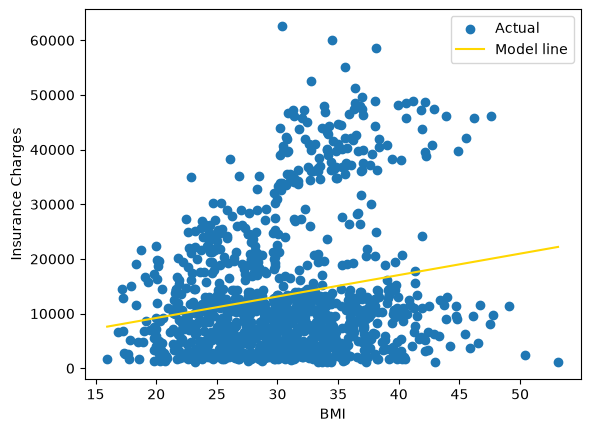

In [21]:
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
Xtr["bmi"].values[order],
pred_train[order],
color="gold", label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")
plt.legend() 
plt.show()

In [46]:
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])

Coefficients: [ 2.56975706e+02  3.37092552e+02  4.25278784e+02 -1.85916916e+01
  2.36511289e+04 -3.70677326e+02 -6.57864297e+02 -8.09799354e+02]
Intercept: -11931.21905032667
First predictions: [ 8969.55027444  7068.74744287 36858.41091155  9454.67850053
 26973.17345656]


In [24]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
poly = make_pipeline(
PolynomialFeatures(degree=2, include_bias=False),
LinearRegression()
)
poly.fit(X_train[["bmi"]], y_train)
poly_pred = poly.predict(X_test[["bmi"]])
print(poly_pred[:5])

[11216.18332138 13577.92065987 12117.12511762 11524.66542818
 14342.99760809]


In [25]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, pred_multi)
print("MSE:", mse)

MSE: 33596915.851361446


In [28]:
import numpy as np
x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)
m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
db = (-2/len(x))*np.sum(y_demo-yhat)
m -= lr*dm
b -= lr*db
print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2))

0.44 0.12
Prediction at x=6: 2.76


Ridge R2: 0.784
Lasso R2: 0.784
ElasticNet R2: 0.779
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.742
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     380.9
Date:                Wed, 18 Nov 2026   Prob (F-statistic):          1.32e-305
Time:                        14:56:53   Log-Likelihood:                -10845.
No. Observations:                1070   AIC:                         2.171e+04
Df Residuals:                    1061   BIC:                         2.175e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

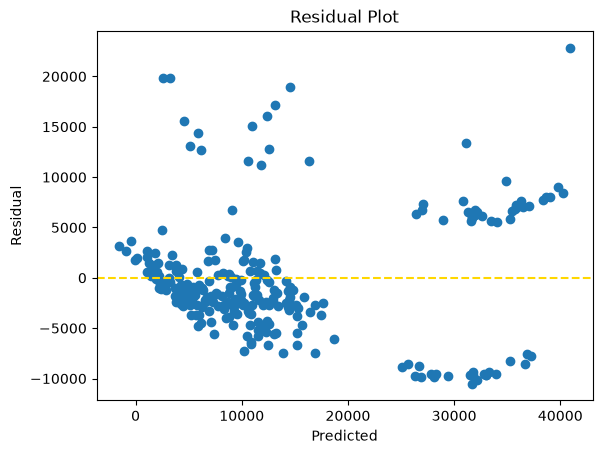

In [43]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
models = {
 "Ridge": Ridge(alpha=1.0),
 "Lasso": Lasso(alpha=0.1, max_iter=10000),
 "ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}
from sklearn.metrics import r2_score
for name, alg in models.items():
    pipe = make_pipeline(StandardScaler(), alg)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(name, "R2:", round(r2_score(y_test,p),3))
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print(ols.summary())
residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="Gold", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

In [45]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
for degree in [1, 2, 5, 10]:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )
    model.fit(X_train[["bmi"]], y_train)
    tr = model.predict(X_train[["bmi"]])
    te = model.predict(X_test[["bmi"]])
    print(degree,
          mean_squared_error(y_train,tr),
          mean_squared_error(y_test,te))

1 138714176.8150972 149085057.03839505
2 138335429.78255913 150472750.8687849
5 137769021.31111908 153231419.0954079
10 138140862.01362512 152713939.7941249


In [44]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_multi)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 4181.19447375365
MSE: 33596915.851361446
RMSE: 5796.284659276272
R2: 0.7835929767120724
